# Genetic algorithms: evolving a set of weights

A **genetic algorithm (GA)** searches for useful solutions by maintaining a population of candidates. Candidates with higher scores contribute to the next generation; recombination and random changes provide new candidates to try. The biological vocabulary is an analogy: we are manipulating arrays of numbers, not simulating genetics in detail.

This notebook uses a deliberately simple objective so that we can connect each operation to its effect on the answer. It is a demonstration of the search process, not a problem that requires a GA to solve.

## Learning goals

By the end, you should be able to:

- Identify the genes, chromosomes, population, and fitness function in the code.
- Explain how selection, crossover, mutation, and elitism affect the next generation.
- Read a fitness history without assuming that improvement proves convergence.
- Distinguish an initialization range from a constraint on the search.

## Before you run

You will need Python 3, NumPy, Matplotlib, and the accompanying `ga.py` file. Run this notebook with `JupyterNotebooks/Week12` as the working directory so that `import ga` finds that helper module. Run the cells in order.

The supplied example runs **10,000 generations** and prints the entire initial and final populations. For a first classroom experiment, you can change `num_generations` to `100` or `1000`. Keep `print_output = False` unless you are examining a very short run. Random initialization and mutation mean that your results will differ from the saved output. For a repeatable experiment in the same environment, insert `np.random.seed(42)` immediately before the initial population is generated.

## The algorithm at a glance

1. **Initialize once:** generate a population of candidate weight vectors.
2. **Evaluate:** compute a fitness score for every candidate.
3. **Select:** retain the highest-scoring candidates as parents.
4. **Recombine:** copy parts of two parents into each offspring.
5. **Mutate:** perturb selected entries of each offspring.
6. **Replace:** form the next population from the retained parents and offspring.
7. Repeat steps **2–6** for the chosen number of generations.

The population is not regenerated from scratch on each iteration. This implementation stops after a fixed number of generations; it does not test for convergence.

## 1. What are we optimizing?

The six inputs are fixed:

$$\mathbf{x}=(4,-2,7,5,-11,1).$$

A candidate solution is a vector of six adjustable weights,
$\mathbf{w}=(w_1,w_2,w_3,w_4,w_5,w_6)$. Its fitness is the dot product

$$f(\mathbf{w})=\mathbf{w}\cdot\mathbf{x}
=4w_1-2w_2+7w_3+5w_4-11w_5+w_6.$$

We want **larger** fitness values. For example, $\mathbf{w}=(1,1,1,1,1,1)$ has fitness $4$, while $\mathbf{w}=(1,-1,1,1,-1,1)$ has fitness $30$. Changing the signs of the second and fifth weights makes their contributions positive.

This is not a regression fit: there are no measured target values, residuals, or training data. We are maximizing a single linear expression.

### A crucial limitation: there is no finite maximum

The code places **no bounds on the weights**. Increasing $w_3$ by $1$, for example, always increases fitness by $7$. There is therefore no largest possible fitness and no finite optimal weight vector.

The interval `[-500, 500)` is only the range used to **initialize** the population. Mutation can subsequently move weights outside that interval. A rising fitness curve shows progress toward larger scores, not convergence to a well-defined maximum.

For comparison, if we imposed the constraint $-500\leq w_i\leq500$ on every generation, the exact optimum would be

$$\mathbf{w}_*=(500,-500,500,500,-500,500),\qquad
f(\mathbf{w}_*)=500\sum_i|x_i|=15{,}000.$$

That is a benchmark for a **modified, bounded problem**, not an upper limit for the code below.

**Pause and predict:** Which direction should each weight move to improve the score? Which weight produces the largest change in fitness for a unit change in the favorable direction?

### Store the fixed inputs

`equation_inputs` holds $\mathbf{x}$, and `num_weights` sets the chromosome length. The weights themselves will be stored in the population array. Leave the six-input example unchanged on your first run; the crossover and mutation discussion below refers to this setup.

In [1]:
# Inputs of the equation.
equation_inputs = [4,-2,7,5,-11,1]
#equation_inputs = [1,-1,1,1,-1,1]
# Number of the weights we are looking to optimize.
num_weights = len(equation_inputs)

## 2. Represent the population

Each **gene** is one floating-point weight. A **chromosome** (or individual) is a row containing all six weights, and the **population** is a two-dimensional NumPy array.

| Code quantity | Meaning | Value in this example |
| --- | --- | --- |
| `num_weights` | Genes per individual | 6 |
| `sol_per_pop` | Individuals per generation | 10 |
| `num_parents_mating` | Individuals retained as parents | 2 |
| `pop_size` | Shape of the population array | `(10, 6)` |

Thus `new_population[i, j]` is weight $j+1$ in individual $i$ (Python indices start at zero). The settings below define the array shape; the random population is created later in the main execution cell.

Population size controls how many candidates are considered at once. Keeping only the best two of ten individuals creates a small breeding pool: the other eight individuals do not pass their genes to the next generation. This can improve scores quickly, but it can also remove diversity.

### A two-parent bottleneck: the “inbreeding” analogy

Here “inbreeding” refers informally to repeatedly breeding from a very small pool of related candidates. This is a demonstration of lost genetic diversity, not a biological model of inbreeding depression.

After the first selection, all descendants inherit their unmutated genes from just two individuals. Selection ranks **total fitness**, not each gene separately: a parent can score well overall while carrying an unfavorable weight at one position.

For example, suppose both original parents have negative $w_1$, even though the coefficient of $w_1$ is $+4$. Every descendant will also have negative $w_1$, since crossover only copies values and mutation never changes this position. If the parents have $w_1=-100$ and $w_1=-20$, that contribution can only be $-400$ or $-80$. A hypothetical $w_1=+100$ would contribute $+400$, all other weights held fixed.

The same restriction applies to $w_2$, $w_4$, and $w_5$. Their favorable signs are negative, positive, and negative, respectively. If neither selected parent carries the favorable sign at one of these positions, it cannot reappear later. Even favorable values present in one of the discarded eight individuals are lost. The fixed midpoint crossover also copies these genes in blocks rather than allowing every combination independently.

Weights $w_3$ and $w_6$ are different: mutation can change their signs and keep increasing their contributions. Therefore, an unfavorable inherited gene can lower fitness relative to an otherwise identical candidate, but it does **not** impose a finite ceiling on total fitness or guarantee that a run loses to every other run. Compare restarts after the same number of generations, and inspect the inherited weights as well as the total score.

**Pause and predict:** If both initial parents have negative $w_1$ and negative $w_3$, which sign can this implementation eventually repair? Use the printed `Original 2 parents` and final weights to check your explanation.



In [2]:
import numpy as np

sol_per_pop = 10
num_parents_mating = 2

# Defining the population size.
pop_size = (sol_per_pop,num_weights) # The population will have sol_per_pop chromosome where each chromosome has num_weights genes.



## 3. Follow one generation through `ga.py`

The next cell uses four functions from the local helper module. Open `ga.py` alongside the notebook to connect these descriptions to the implementation.

### Fitness: score each row

`ga.cal_pop_fitness(equation_inputs, new_population)` multiplies each row by the six inputs and sums across columns (`axis=1`). A `(10, 6)` population produces a fitness array of shape `(10,)`: one score per individual. Fitness can be negative; a less negative score is still better in this maximization problem.

### Selection: keep the best two

`ga.select_mating_pool(...)` repeatedly selects the highest remaining score and copies that individual's weights into the parent array. This is deterministic selection of the top individuals, not random sampling weighted by fitness. Ties are resolved by taking the first matching index.

Implementation detail: the helper overwrites selected entries of the supplied fitness array with a very negative sentinel. Treat that array as modified after selection. The next generation's fitness is computed afresh.

### Crossover: combine two halves

`ga.crossover(...)` produces **8 offspring**, leaving room for the two retained parents. For six genes, the split is after the third gene:

```text
Parent A:  [a1, a2, a3 | a4, a5, a6]
Parent B:  [b1, b2, b3 | b4, b5, b6]
Offspring: [a1, a2, a3 | b4, b5, b6]
```

The helper alternates between parent pairs `(0, 1)` and `(1, 0)`. It does not choose pairs randomly. Crossover rearranges existing gene values; it does not create new numerical values.

### Mutation: introduce new values

The call `ga.mutation(..., num_mutations=2)` adds separate random increments drawn uniformly from `[-1, 1)` to two entries in each offspring.

**The positions are fixed, not randomly chosen.** With six genes and two mutations, the helper changes Python indices `2` and `5`: weights $w_3$ and $w_6$. The other four weights can be inherited and recombined, but cannot acquire values absent from the initial population. This is a limitation of this particular teaching implementation, not a general property of genetic algorithms.

Here both mutated weights have positive coefficients. If their increments are $\delta_3$ and $\delta_6$, the mutation's effect on an offspring's fitness is

$$\Delta f=7\delta_3+\delta_6.$$

A mutation may help or hurt an individual. Selection favors successful changes in subsequent generations.

### Replacement: preserve parents and add offspring

The two parents occupy the first two rows of the next population; the eight mutated offspring fill the remaining rows. Retaining parents unchanged is called **elitism**. Because the best individual survives, the best fitness should not decrease between generations in this example, apart from numerical issues.

**Pause and predict:** Can crossover alone produce a weight larger than every initial value of that weight? Can mutation make an offspring worse while the population's best score stays unchanged?

## 4. Run the search

`best_outputs` records the best fitness **before reproduction** on each loop iteration. After the final replacement, the code evaluates the final population separately. Consequently, the printed final best score may be higher than the last plotted value: the final offspring are not included in the history.

Start with a short run if you want to inspect the printed populations. Setting `print_output = True` also prints intermediate fitness, parents, and offspring for every generation, so use it only for a few generations.

Original Population
[[-280.71010775  400.76863698  390.2318028   202.90930418 -258.01926117
   -66.18370486]
 [-357.28826379  491.74007736 -444.51629112  -66.76419843   36.12411564
   441.61030777]
 [  10.49126088  481.07994942 -430.35392951   44.83675241  269.46176204
  -174.03279116]
 [-345.20747645  251.13900481 -412.08828907   52.2524826   111.0715775
  -115.31791883]
 [-244.49660907  275.29918834 -336.1447391    80.05652601   45.50505241
  -377.73784949]
 [-104.76739385 -164.63287855  376.58593091 -167.5952231   263.28310265
   269.88231832]
 [ -45.85958297  256.68995221 -155.55360396  257.41541751 -390.81338792
   -23.47394444]
 [ 301.80550776  -24.07840274  113.55262372   -4.35101124 -485.79484488
   424.66743552]
 [-405.37660229 -271.57343346 -350.56517053   50.14025785  305.09964657
    75.00376622]
 [-463.14002304   11.32316846 -292.40307786  224.25560349 -343.75670773
   482.5290638 ]]
Final Population
[[ 3.01805508e+02 -2.40784027e+01  7.04093462e+03 -4.35101124e+00
  -4.85

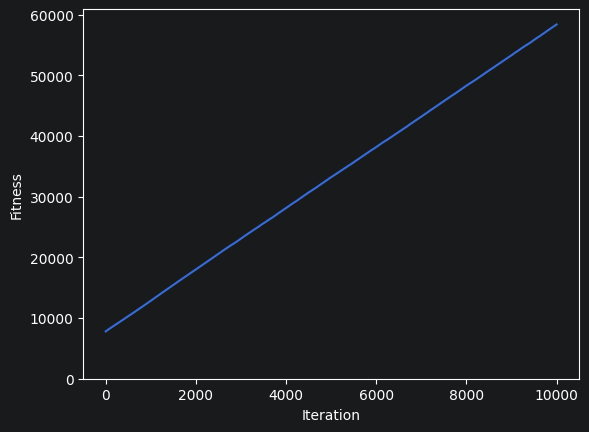

In [3]:
import ga as ga

best_outputs = []
num_generations = 10000
print_output = False

#Creating the initial population.
new_population = np.random.uniform(low=-500.0, high=500.0, size=pop_size)

print("Original Population")
print(new_population)

for generation in range(num_generations):
    if (print_output):
        print("Generation : ", generation)
    # Measuring the fitness of each chromosome in the population.
    fitness = ga.cal_pop_fitness(equation_inputs, new_population)
    if (print_output):
        print("Fitness : ", fitness)

    best_outputs.append(np.max(np.sum(new_population*equation_inputs, axis=1)))
    # The best result in the current iteration.
    if (print_output):
        print("Best result : ", np.max(np.sum(new_population*equation_inputs, axis=1)))
    
    # Selecting the best parents in the population for mating.
    parents = ga.select_mating_pool(new_population, fitness, 
                                      num_parents_mating)
    # save the original parents for later comparison
    if generation == 0:
        original_parents = parents.copy()

    if (print_output):
        print("Parents")
        print(parents)

    # Generating next generation using crossover.
    offspring_crossover = ga.crossover(parents,
                                       offspring_size=(pop_size[0]-parents.shape[0], num_weights))
    if (print_output):
        print("Crossover")
        print(offspring_crossover)

    # Adding some variations to the offspring using mutation.
    offspring_mutation = ga.mutation(offspring_crossover, num_mutations=2)
    if (print_output):
        print("Mutation")
        print(offspring_mutation)

    # Creating the new population based on the parents and offspring.
    new_population[0:parents.shape[0], :] = parents
    new_population[parents.shape[0]:, :] = offspring_mutation
    
    # Print new population
    if (print_output):
        print("New Population")
        print(new_population)


print("Final Population")
print(new_population)

# Getting the best solution after iterating finishing all generations.
#At first, the fitness is calculated for each solution in the final generation.
fitness = ga.cal_pop_fitness(equation_inputs, new_population)
# Then return the index of that solution corresponding to the best fitness.
best_match_idx = np.where(fitness == np.max(fitness))

print("==================================")
print("Original 2 parents : ", original_parents)
print("Original parents fitness : ", ga.cal_pop_fitness(equation_inputs, original_parents))
print("Equation inputs : ", equation_inputs)
print("===================================")
print("Best solution : ", new_population[best_match_idx, :])
print("Best solution fitness : ", fitness[best_match_idx])

import matplotlib.pyplot
matplotlib.pyplot.plot(best_outputs)
matplotlib.pyplot.xlabel("Iteration")
matplotlib.pyplot.ylabel("Fitness")
matplotlib.pyplot.ylim(0)
matplotlib.pyplot.show()



## 5. Interpret the results

The printed **best solution** contains the weight vector or vectors tied for the highest final fitness. The corresponding **best solution fitness** is their dot product with the fixed input vector. Because the code uses `np.where`, ties can return multiple individuals and the printed weights have an extra array dimension.

The plot shows the best score in each recorded generation, not the population's average score or its diversity. Its horizontal axis, labeled “Iteration,” counts generations starting at zero. The plotting code fixes the lower vertical limit at zero, so negative fitness values would not be visible.

When reading your run, ask:

- **Does the best score ever decrease?** Elitism predicts that it should not in this setup.
- **Do the final weights all remain between −500 and 500?** They need not: the two mutated weights are unbounded.
- **Does continued improvement demonstrate convergence?** No. This objective has no finite maximum.
- **Does a high best score imply a diverse population?** No. Many individuals may be very similar; this plot does not measure diversity.

A temporary plateau is also not proof of optimality. It may reflect limited diversity, small mutation steps, or a period without beneficial changes.

## 6. Explore and discuss

Change one feature at a time and record what you changed. Use several random seeds when comparing methods; one fortunate run is not enough to establish that a method is better.

1. **Check the fitness calculation.** Compute the score of `(1, -1, 1, 1, -1, 1)` by hand, then verify that `ga.cal_pop_fitness` returns `30` when given that vector as a one-row population.
2. **Observe inheritance.** Run only a few generations with `print_output = True`. Locate the crossover split and identify the two entries changed by mutation. Explain why the remaining entries come from the initial population.
3. **Compare population settings.** Start with ten individuals and two parents. Then try 20 or 100 individuals while keeping two parents, or keep ten individuals and increase the parent count to four. Change one setting at a time and compare repeated runs with the same generation budget. Larger populations evaluate more candidates per generation; more parents can preserve more inherited diversity.
4. **Make the objective bounded.** As a code exercise, clip mutated offspring to `[-500, 500]` before inserting them into the next population. Compare scores with the analytical benchmark of `15,000`. Explain why the current mutation rule still prevents four weights from evolving to arbitrary new values, including the exact boundary values required by the optimum.
5. **Broaden mutation.** Modify the helper to choose mutation positions randomly, or test `num_mutations=6` to perturb every weight. For the bounded experiment, retain clipping. Compare progress and diversity with the original two-position rule. Save helper changes separately if you want to preserve the original example; other notebooks may also import `ga.py`.
6. **Design a stopping rule.** For the bounded version, propose a fitness tolerance relative to `15,000` and a maximum-generation limit. Why is “no improvement for several generations” a useful practical rule but not a proof of global optimality?

## What this example teaches

Selection preserves strong candidates, crossover combines existing pieces, and mutation introduces new values. Their effects depend on the representation and the exact implementation. Before trusting an optimization result, define the feasible region, inspect what the operators can actually change, and decide what evidence would count as success.

For this linear objective, the bounded optimum can be found directly by inspecting coefficient signs. The value of the GA here is to make the mechanics visible before considering problems whose good solutions are harder to construct analytically.

## 7. Repeat the simulation 100 times

One run illustrates inheritance; repeated runs show how much the outcome depends on initialization and mutation. The cells below run the **entire search from a fresh random population 100 times**, using the current `sol_per_pop`, `num_parents_mating`, and `num_generations` settings. With the setup above, every run uses ten individuals, two parents, and 10,000 generations: one million generations across the experiment.

The function uses the same `ga.py` selection, crossover, mutation, and elitist replacement as the original cell. It evaluates fitness **after the final replacement**, so the recorded value is the true final-population maximum, not the last entry of the original pre-reproduction history. It does not print populations or make a plot during each run.

Each restart has a distinct, recorded seed. Rerunning the experiment with the same seeds and settings reproduces the results in the same software environment. The function restores NumPy's random state afterward so the experiment does not alter the random stream used by other cells.

The horizontal axis of the new plot is **simulation run number (1–100)**, not generation number. Each point summarizes one complete search; there is no reason for scores to rise from left to right. The full experiment may take a while. For a quick preview, temporarily reduce `num_runs` or `generations_per_run`, then restore them for the 100-run comparison.


In [4]:
def run_ga_trial(equation_inputs, population_size, parent_count, generations, seed):
    """Run one fresh six-weight search and return its final best and founders."""
    coefficients = np.asarray(equation_inputs, dtype=float)
    if coefficients.shape != (6,):
        raise ValueError("This experiment uses six weights and two mutations.")
    if not 2 <= parent_count < population_size:
        raise ValueError("Use at least two parents and leave room for offspring.")
    if generations < 1:
        raise ValueError("Use at least one generation to select the original parents.")

    random_state = np.random.get_state()
    try:
        np.random.seed(seed)
        population = np.random.uniform(-500.0, 500.0, (population_size, 6))
        for generation in range(generations):
            scores = ga.cal_pop_fitness(coefficients, population)
            parents = ga.select_mating_pool(population, scores, parent_count)
            if generation == 0:
                founders = parents.copy()
            children = ga.crossover(parents, (population_size - parent_count, 6))
            children = ga.mutation(children, num_mutations=2)
            population[:parent_count] = parents
            population[parent_count:] = children

        final_scores = ga.cal_pop_fitness(coefficients, population)
        best_index = np.argmax(final_scores)
        return {
            "seed": seed,
            "final_fitness": float(final_scores[best_index]),
            "best_weights": population[best_index].copy(),
            "original_parents": founders,
        }
    finally:
        np.random.set_state(random_state)


In [5]:
# Run the setup/import cells above first (np, ga, and the search settings).
num_runs = 100
generations_per_run = num_generations
base_seed = 441
trial_seeds = np.arange(base_seed, base_seed + num_runs)
# Save the settings alongside the results for later comparisons.
experiment_settings = {
    "equation_inputs": np.asarray(equation_inputs).copy(),
    "population_size": sol_per_pop,
    "parent_count": num_parents_mating,
    "generations": generations_per_run,
}

trial_results = []
for run_number, seed in enumerate(trial_seeds, start=1):
    trial_results.append(run_ga_trial(**experiment_settings, seed=int(seed)))
    if run_number % 10 == 0 or run_number == num_runs:
        print(f"Completed {run_number}/{num_runs} runs")

final_fitnesses = np.array([result["final_fitness"] for result in trial_results])
print(f"Final fitness: min={final_fitnesses.min():.2f}, "
      f"median={np.median(final_fitnesses):.2f}, max={final_fitnesses.max():.2f}")


Completed 10/100 runs
Completed 20/100 runs
Completed 30/100 runs
Completed 40/100 runs
Completed 50/100 runs
Completed 60/100 runs
Completed 70/100 runs
Completed 80/100 runs
Completed 90/100 runs
Completed 100/100 runs
Final fitness: min=50662.73, median=58111.27, max=62361.08


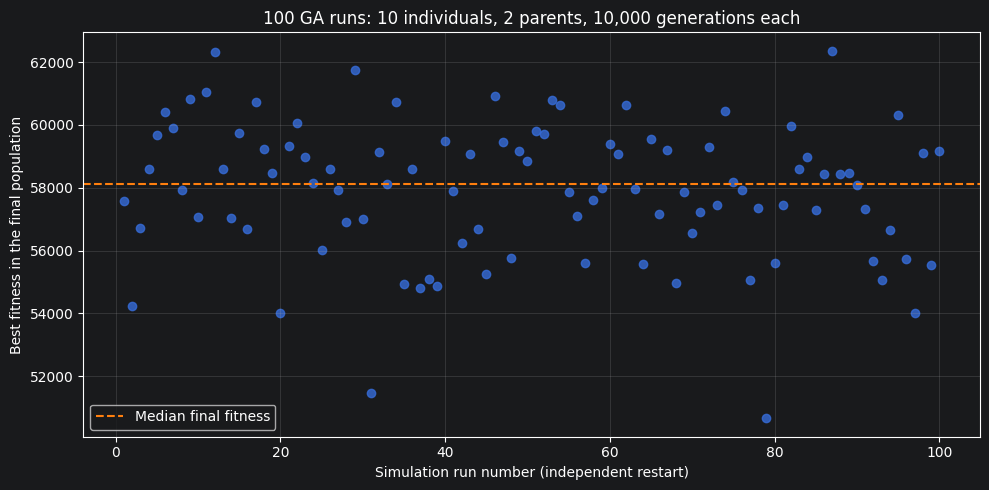

In [6]:
import matplotlib.pyplot as plt

run_numbers = np.arange(1, len(trial_results) + 1)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(run_numbers, final_fitnesses, alpha=0.8)
ax.axhline(np.median(final_fitnesses), color="tab:orange", linestyle="--",
           label="Median final fitness")
ax.set_xlabel("Simulation run number (independent restart)")
ax.set_ylabel("Best fitness in the final population")
ax.set_title(
    f"{len(trial_results)} GA runs: {experiment_settings['population_size']} individuals, "
    f"{experiment_settings['parent_count']} parents, "
    f"{experiment_settings['generations']:,} generations each"
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


### Investigate a low-scoring run

Variation in final fitness reflects both the initial breeding pool and random mutation. The scatter plot alone cannot establish that an unfavorable inherited sign caused a particular low score: the magnitudes of all six weights contribute, and the two mutated weights can partly compensate.

The next cell inspects the lowest-scoring restart. For each **unmutated** gene, it asks whether every original parent had a strictly unfavorable sign. These are positions where a favorable sign could not be recovered. It also prints that gene's contribution in the final winner. An empty list means this particular sign test found no such position; it does not mean diversity was preserved or that the inherited magnitudes were ideal.

Compare this run with the highest-scoring one by replacing `np.argmin` with `np.argmax`. To test remedies, repeat the experiment with more parents or mutation at all positions, keeping the generation budget fixed and recording the changed settings. Neither the plot nor this diagnostic supplies a global optimum for the unbounded objective.


In [7]:
lowest_run_index = int(np.argmin(final_fitnesses))
lowest_run = trial_results[lowest_run_index]
unmutated_indices = np.array([0, 1, 3, 4])  # weights 1, 2, 4, 5
coefficients = experiment_settings["equation_inputs"]
founder_contributions = lowest_run["original_parents"][:, unmutated_indices] * coefficients[unmutated_indices]
trapped_indices = unmutated_indices[np.all(founder_contributions < 0, axis=0)]

print(f"Lowest-scoring run: {lowest_run_index + 1}, seed={lowest_run['seed']}")
print("Original parents:\n", lowest_run["original_parents"])
print("Final best weights:", lowest_run["best_weights"])
print("Final fitness:", lowest_run["final_fitness"])
print("Unmutated weights with unfavorable signs in every founder:",
      (trapped_indices + 1).tolist())
print("Final contributions from those weights:",
      lowest_run["best_weights"][trapped_indices] * coefficients[trapped_indices])


Lowest-scoring run: 79, seed=519
Original parents:
 [[  58.09698751  407.39285884  283.73225706   75.95619875  144.48531146
   -34.58523599]
 [-118.66267572   21.12645586  317.82724839 -145.85764239  192.85579509
  -143.12785161]]
Final best weights: [-118.66267572   21.12645586 7211.70980047   75.95619875  144.48531146
 1907.22300925]
Final fitness: 50662.730565643804
Unmutated weights with unfavorable signs in every founder: [2, 5]
Final contributions from those weights: [  -42.25291172 -1589.33842608]


In [8]:
# now, repeat the same analysis, but keeping 4 parents instead of 2, and increase the population size to 20. This should reduce the number of trapped weights and improve the final fitness scores.

sol_per_pop = 20
num_parents_mating = 4

# Defining the population size.
pop_size = (sol_per_pop,num_weights) # The population will have sol_per_pop chromosome where each chromosome has num_weights genes.

# Run the setup/import cells above first (np, ga, and the search settings).
num_runs = 100
generations_per_run = num_generations
base_seed = 441
trial_seeds = np.arange(base_seed, base_seed + num_runs)
# Save the settings alongside the results for later comparisons.
experiment_settings = {
    "equation_inputs": np.asarray(equation_inputs).copy(),
    "population_size": sol_per_pop,
    "parent_count": num_parents_mating,
    "generations": generations_per_run,
}

trial_results = []
for run_number, seed in enumerate(trial_seeds, start=1):
    trial_results.append(run_ga_trial(**experiment_settings, seed=int(seed)))
    if run_number % 10 == 0 or run_number == num_runs:
        print(f"Completed {run_number}/{num_runs} runs")

final_fitnesses = np.array([result["final_fitness"] for result in trial_results])
print(f"Final fitness: min={final_fitnesses.min():.2f}, "
      f"median={np.median(final_fitnesses):.2f}, max={final_fitnesses.max():.2f}")


Completed 10/100 runs
Completed 20/100 runs
Completed 30/100 runs
Completed 40/100 runs
Completed 50/100 runs
Completed 60/100 runs
Completed 70/100 runs
Completed 80/100 runs
Completed 90/100 runs
Completed 100/100 runs
Final fitness: min=59853.07, median=63493.72, max=67251.68


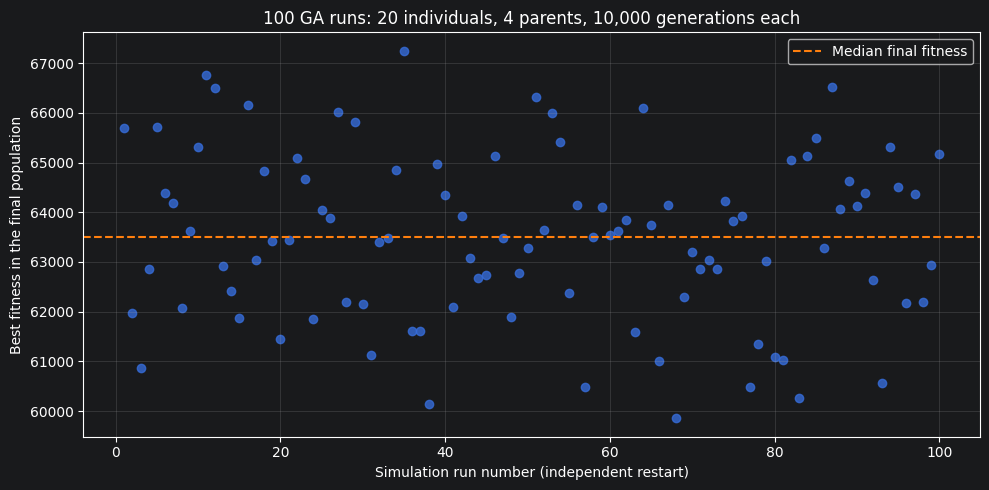

In [9]:
import matplotlib.pyplot as plt

run_numbers = np.arange(1, len(trial_results) + 1)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(run_numbers, final_fitnesses, alpha=0.8)
ax.axhline(np.median(final_fitnesses), color="tab:orange", linestyle="--",
           label="Median final fitness")
ax.set_xlabel("Simulation run number (independent restart)")
ax.set_ylabel("Best fitness in the final population")
ax.set_title(
    f"{len(trial_results)} GA runs: {experiment_settings['population_size']} individuals, "
    f"{experiment_settings['parent_count']} parents, "
    f"{experiment_settings['generations']:,} generations each"
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()